# MoE comparisons: four heads on a shared, frozen backbone

**What it does.** Classifies 64x64 images into 200 classes. A small ResNet *backbone* is trained once and then **frozen**; four different *heads* are trained on top of it and compared on the validation set:

| model | idea |
|---|---|
| **CNN** | baseline: one ordinary dense layer |
| **MoE** | several small expert networks and a *gate* that decides how much each expert counts for an image |
| **pMoE** | each expert looks only at the few image patches its router picks |
| **MGE** | one expert on each depth of the backbone (shallow, middle, deep); their answers are averaged |

**How to run**
1. Open the notebook on a machine with a GPU if you can (RunPod, Colab or local, see the README).
2. Run the cells from top to bottom. The cells you may want to edit are **Settings** and **Choose the backbone**.
3. In **Choose the backbone**, write the path of a saved backbone in `BACKBONE_PATH`, or leave it `None` to train a new one (it is saved under an automatic name in `MoE_comparisons/models/`).
4. Each model writes a log to `MoE_comparisons/history_logs/` and its weights to `MoE_comparisons/models/` as soon as it is trained. To retrain a single model, run only its cell: the backbone is not trained again.
5. To look at results again **without training**, set `USE_SAVED = True` (first code cell) and run everything: the backbone, head weights and logs are loaded from disk (or from GitHub on a new pod).

Only the **validation** split is used here. The test split is not touched.

This notebook does not depend on any other notebook: `pMoE_MGE_finetune_v2.ipynb` can use a backbone saved here by writing its path, and the other way round.

In [10]:
USE_SAVED = False   # True: load the saved backbone, head weights and logs instead of training (analyse old runs)

import os, sys, subprocess
import warnings
warnings.filterwarnings('ignore')
os.environ.setdefault('TF_FORCE_GPU_ALLOW_GROWTH', 'true')   # take GPU memory as needed, not all of it at start (kernels can then share a GPU)

REPO_URL = 'https://github.com/durak-dev/ImageClassification.git'
IN_COLAB = 'google.colab' in sys.modules

if IN_COLAB:
    # Colab starts with an empty VM: clone the repo (code AND data live in it).
    # On later runs the folder already exists, so just pull the newest commits.
    ROOT = '/content/ImageClassification'
    if not os.path.exists(ROOT):
        subprocess.run(['git', 'clone', REPO_URL, ROOT], check=True)
    else:
        # fetch + hard reset instead of `pull`: always lands on the newest origin commit, even if the VM copy diverged
        subprocess.run(['git', '-C', ROOT, 'fetch', 'origin'], check=True)
        subprocess.run(['git', '-C', ROOT, 'reset', '--hard', '@{u}'], check=True)
else:
    # Local: the notebook sits in the project root, but also work if it was
    # started from a subfolder.
    cwd = os.path.abspath(os.getcwd())
    ROOT = cwd if os.path.isdir(os.path.join(cwd, 'utils')) else os.path.dirname(cwd)

os.chdir(ROOT)
sys.path.insert(0, ROOT)          # so `import utils.funcs` finds OUR utils folder

DATA_DIR = os.path.join(ROOT, 'data')
ORIG_DIR = os.path.join(DATA_DIR, 'original')            # raw images/ + labels/ (placed manually, never modified)
MANIFEST_PATH = os.path.join(DATA_DIR, 'split_manifest.csv')   # which file belongs to which split
SEED = 42
NB_DIR = 'MoE_comparisons'   # this notebook's output folder (relative to the project root)
MODELS_DIR = f'{NB_DIR}/models'          # backbones and head weights
HISTORY_DIR = f'{NB_DIR}/history_logs'   # one CSV log per training run
os.makedirs(MODELS_DIR, exist_ok=True)
os.makedirs(HISTORY_DIR, exist_ok=True)
print('Running on:', 'Google Colab' if IN_COLAB else 'local machine')
print('Project root:', ROOT)

Running on: local machine
Project root: /workspace/ImageClassification


In [9]:
# the kernel survives between runs: drop every cached utils module so the code git just pulled is what gets imported
for _m in [m for m in sys.modules if m == 'utils' or m.startswith('utils.')]:
    del sys.modules[_m]
from utils.funcs import *
from utils import config, github_sync, plotting, resnet
from utils.github_sync import save_csv, load_csv, push_files
from utils.MoE import *

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow.keras import layers
from sklearn.metrics import f1_score
tf.keras.mixed_precision.set_global_policy('mixed_float16')   # ~2x faster on the GPU

### Where the results go
Logs go to `MoE_comparisons/history_logs/`, backbones and model weights to `MoE_comparisons/models/` (this notebook's own output folder). A RunPod pod or Colab VM loses its disk when it ends, so the next cell offers two ways to keep them:
* **Push to GitHub:** paste a GitHub token into the box (hidden, kept in memory only). Everything is then committed to the `checkpoints` branch as soon as it is written, and a new pod downloads the saved backbone from there instead of training it again. Leave the box empty to skip.
* **Copy to your PC:** run `.\pull_results.ps1 -Ip <ip> -Port <port>` before you terminate the pod (see the README).

Running locally you can ignore this cell: everything stays in the project folder.

In [11]:
# Is the disk temporary? Colab VM, or a RunPod pod (pod_bootstrap.sh clones the repo into /workspace).
ON_POD = ROOT.startswith('/workspace/') or bool(os.environ.get('RUNPOD_POD_ID'))
REMOTE = IN_COLAB or ON_POD
if REMOTE:
    config.ensure_github()      # asks once for a GitHub token (hidden box, kept in memory only); empty = no upload
USE_GITHUB = REMOTE and config.github_ready()

if USE_GITHUB:
    _, repo, branch = config.github_settings()
    print(f'Results -> GitHub {repo}@{branch}: every log, backbone and weight file is committed when it is written')
elif ON_POD:
    print('Results stay on the pod. Copy them to your PC before terminating it:  .\\pull_results.ps1 -Ip <ip> -Port <port>')
else:
    print(f'Results -> local folders ({HISTORY_DIR}/, {MODELS_DIR}/)')

Results -> GitHub durak-dev/ImageClassification@checkpoints: every log, backbone and weight file is committed when it is written


In [4]:
# Recreate data/{split}/ with the corrected images + labels if they are missing (fresh Colab VM).
# Needs split_manifest.csv, data/original/ and the two checkpoint files from the cloned repo.
if not all(os.path.exists(os.path.join(split_dir(DATA_DIR, s, 'labels'), CORRECTED_LABELS_FILE)) for s in SPLITS):
    materialize_splits(ORIG_DIR, DATA_DIR, pd.read_csv(MANIFEST_PATH))
    rebuild_corrected(pd.read_csv(os.path.join(ROOT, 'checkpoints', 'df_fixed.csv')), DATA_DIR,
                      labels_corrected=pd.read_csv(os.path.join(ROOT, 'checkpoints', 'labels_corrected.csv')))

train: 42000 images
val  : 9000 images
test : 9000 images
test : 9000 images written, 3724 of 9000 corrected -> /workspace/ImageClassification/data/test/images_corrected
train: 42000 images written, 17469 of 42000 corrected -> /workspace/ImageClassification/data/train/images_corrected
val  : 9000 images written, 3906 of 9000 corrected -> /workspace/ImageClassification/data/val/images_corrected
labels_corrected.csv written for test, train, val


In [5]:
dfs = {s: pd.read_csv(os.path.join(split_dir(DATA_DIR, s, "labels"), CORRECTED_LABELS_FILE)) for s in ["train", "val", "test"]}
classes = sorted(dfs["train"]["class_id"].unique())
class_to_idx = {c: i for i, c in enumerate(classes)}

## Data
Images are resized to 64x64. **Only the training set is rebalanced** (classes with few images are repeated up to the median class size); validation and test stay as they are.

In [6]:
SIZE, BATCH, AUTOTUNE = 64, 256, tf.data.AUTOTUNE
CLASS_BALANCE = 'oversample'         # train set only: None | "oversample" | "undersample"  (see funcs.balance_frame)
CLASS_BALANCE_TARGET = 'median'  # images per class: None (max / min) | "min" | "median" | "max" | int

def load(path, y):
    img = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
    img = tf.image.resize(img, (SIZE, SIZE))
    return tf.cast(tf.round(img), tf.uint8), y        # uint8: 4x smaller in the RAM cache below

def make_ds(split, shuffle):
    df = dfs[split]
    if split == "train" and CLASS_BALANCE:      # never resample val / test
        df = balance_frame(df, CLASS_BALANCE, CLASS_BALANCE_TARGET, seed=SEED)
        n = df["class_id"].value_counts()
        print(f"train balanced ({CLASS_BALANCE}): {len(df)} images, {n.min()}-{n.max()} per class")
    paths = (f"{DATA_DIR}/{split}/images_corrected/" + df["filename"].astype(str)).values
    labels = df["class_id"].map(class_to_idx)
    assert labels.notna().all(), f"{split} has labels not present in train"
    ds = tf.data.Dataset.from_tensor_slices((paths, labels.values.astype("int32")))
    ds = ds.map(load, num_parallel_calls=AUTOTUNE).cache()   # decode + resize ONCE; later epochs read from RAM
    if shuffle:
        ds = ds.shuffle(len(df), seed=SEED)                  # after cache(), so the order still changes every epoch
    ds = ds.batch(BATCH).map(lambda x, y: (tf.cast(x, tf.float32), y), num_parallel_calls=AUTOTUNE)
    return ds.prefetch(AUTOTUNE)

train, val, test = make_ds("train", True), make_ds("val", False), make_ds("test", False)
print(len(classes), "classes")
print(dfs["train"]["filename"].iloc[0], os.path.exists(f"{DATA_DIR}/train/images_corrected/" + str(dfs["train"]["filename"].iloc[0])))
for x, y in train.take(1):
    print(x.shape, x.dtype, float(tf.reduce_min(x)), float(tf.reduce_max(x)))

train balanced (oversample): 38600 images, 193-193 per class


W0000 00:00:1795109625.963028   48273 gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was false.
I0000 00:00:1795109625.965491   48273 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 46733 MB memory:  -> device: 0, name: NVIDIA RTX A6000, pci bus id: 0000:45:00.0, compute capability: 8.6


200 classes
image_000002.JPEG True
(256, 64, 64, 3) <dtype: 'float32'> 0.0 255.0


## Settings
Everything you might want to change is in the next cell.

* **Backbone** (only used when `BACKBONE_PATH = None`) - `drop` is the dropout inside the backbone and `weight_decay` the AdamW weight decay. Raise them if the backbone overfits.
* **Heads** - every model trains only its own head on top of the frozen backbone, for at most `EPOCHS` epochs. Training stops early when the validation loss has not improved for `PATIENCE` epochs.

In [34]:
# ======== Settings ========

# --- backbone training (only used when BACKBONE_PATH = None)
BACKBONE = dict(
    blocks=(2, 3, 4, 2),   # residual blocks per stage (was 3, 6, 8, 3); fewer blocks = faster epochs
    drop=0.3,              # dropout inside the backbone (after stages 2 and 3)
    head_drop=0.3,         # dropout of the linear head used only for pretraining
    epochs=30,             # pretraining epochs = length of the cosine schedule
    lr=3e-3,               # PEAK learning rate (linear warmup, then cosine decay to 0)
    warmup_epochs=2,
    weight_decay=0.05,     # AdamW, applied as lr * wd per step (1e-4 was practically none); not on bias / BN
    label_smoothing=0.1,   # ~10% of the labels are wrong: don't let the model be 100% sure
)

# --- heads: every model trains its own head on the frozen backbone
EPOCHS = 10               # head training epochs (early stopping after PATIENCE epochs without improvement)
PATIENCE = 4              # early stopping: epochs without a better val loss (heads and backbone)
LR = 0.01                 # head PEAK learning rate (warmup + cosine, see HEAD_LR)
USE_AUG = True            # random flip + shift for every model
FEATURE_DROP = 0.3        # CNN / MoE: dropout on the pooled s3 features
N_EXPERTS = 8             # MoE / pMoE: number of experts
BALANCE = 0.1            # MoE: weight of the load-balancing loss
L_PATCHES = 8             # pMoE: patches each expert keeps (at most 64)
DIVERSITY_WEIGHT = 0.1    # MGE: weight of the diversity penalty

aug = tf.keras.Sequential([layers.RandomFlip("horizontal"), layers.RandomTranslation(0.1, 0.1)])
AUG = aug if USE_AUG else None
STEPS = int(train.cardinality())   # batches per epoch
# every head: 1 epoch linear warmup to LR, then cosine decay to 0 at EPOCHS
HEAD_LR = tf.keras.optimizers.schedules.CosineDecay(0.0, decay_steps=(EPOCHS - 1) * STEPS, warmup_target=LR, warmup_steps=STEPS)


def run(model, name, epochs=EPOCHS, gate=False, initial_epoch=0, save=True):
    """Train `model` and return its History; with USE_SAVED, load its saved weights and log instead.
    Log: <HISTORY_DIR>/<name>.csv, weights (best epoch): <MODELS_DIR>/<name>.weights.h5, both pushed to GitHub if USE_GITHUB.
    initial_epoch > 0 continues an earlier run: its epochs are appended to the same log."""
    log_path, weights_path = f'{HISTORY_DIR}/{name}.csv', f'{MODELS_DIR}/{name}.weights.h5'
    if USE_SAVED:
        for p in (log_path, weights_path):
            if not resnet.fetch_if_missing(p, USE_GITHUB):
                raise FileNotFoundError(f'{p} is missing: train this run first (USE_SAVED = False)')
        model.load_weights(weights_path)
        history = tf.keras.callbacks.History()
        history.history = pd.read_csv(log_path).to_dict('list')
    else:
        callbacks = ([GateMonitor(val)] if gate else []) + [       # before CSVLogger, so their values land in the log
            MacroF1(val),
            tf.keras.callbacks.CSVLogger(log_path, append=initial_epoch > 0),
            tf.keras.callbacks.EarlyStopping(patience=PATIENCE, restore_best_weights=True)]
        history = model.fit(train, validation_data=val, initial_epoch=initial_epoch, epochs=initial_epoch + epochs,
                            callbacks=callbacks)
        files = {log_path: log_path}
        if save:
            model.save_weights(weights_path)
            files[weights_path] = weights_path
        if USE_GITHUB:
            push_files(files, f'run: {name}')
    plot_history(history)
    return history

## The backbone
A ResNet written for 64x64 images (no early downsampling). Its code is the function `backbone` in the first code cell below, so you can change it right there (layers, widths; the number of blocks per stage is `BACKBONE['blocks']`). It has four stages; the outputs of stages 2, 3 and 4 (`s1`, `s2`, `s3`) are what the heads use:

```
image 64x64 -> augmentation -> stem -> stage 1 -> stage 2 (s1: 32x32x64) -> stage 3 (s2: 16x16x128) -> stage 4 (s3: 8x8x256)
```

| model | reads |
|---|---|
| CNN, MoE | `s3`, averaged to 256 numbers |
| pMoE | `s3` as 64 patches (the 8x8 grid) of 256 numbers |
| MGE | `s1`, `s2` and `s3` |

A saved backbone is a complete `.keras` model (layers and weights), so it can be loaded without this code: editing `backbone` only matters when you train a **new** backbone, and old files keep the layers they were trained with. The cell after the code defines `train_backbone()` (a plain linear head); the one after that chooses the backbone all heads use.

In [15]:
# The backbone: edit it freely. It must return [s1, s2, s3] (shallow -> deep); the settings come from BACKBONE above.
# Only used when training a NEW backbone: a saved backbone carries its own layers, so editing this cell does not change it.
def backbone(inp):
    """Conv layers only (no augmentation) -> [s1, s2, s3], shallow -> deep."""
    drop, (n1, n2, n3, n4) = BACKBONE['drop'], BACKBONE['blocks']
    x = layers.Rescaling(1 / 255)(inp)
    x = layers.Conv2D(32, 3, padding="same", use_bias=False)(x)     # stem
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)

    # stage 1: 64 x 64 x 32, no downsampling
    for _ in range(n1):
        x = res_block(x, 32, downsample=False)

    # stage 2: 32 x 32 x 64
    x = res_block(x, 64)
    for _ in range(n2 - 1):
        x = res_block(x, 64, downsample=False)
    s1 = x                                        # MGE expert 0
    x = layers.SpatialDropout2D(drop)(x)

    # stage 3: 16 x 16 x 128
    x = res_block(x, 128)
    for _ in range(n3 - 1):
        x = res_block(x, 128, downsample=False)
    s2 = x                                        # MGE expert 1
    x = layers.SpatialDropout2D(drop)(x)

    # stage 4: 8 x 8 x 256
    x = res_block(x, 256)
    for _ in range(n4 - 1):
        x = res_block(x, 256, downsample=False)
    s3 = x                                        # MGE expert 2, pMoE, CNN / MoE (pooled)

    return [s1, s2, s3]

In [16]:
# Train a NEW backbone (only runs when BACKBONE_PATH is None in the cell below).
# It is trained with a plain linear head, then saved as a complete .keras file (layers + weights) in MODELS_DIR under an
# automatic, unique name.
def train_backbone():
    tf.keras.backend.clear_session()
    trunk_in = tf.keras.Input((SIZE, SIZE, 3))
    trunk = tf.keras.Model(trunk_in, backbone(trunk_in), name='trunk')
    path = resnet.new_trunk_path(MODELS_DIR, trunk)
    inp = tf.keras.Input((SIZE, SIZE, 3))
    x = AUG(inp) if AUG is not None else inp
    x = layers.GlobalAveragePooling2D()(trunk(x)[-1])
    x = layers.Dropout(BACKBONE['head_drop'])(x)
    pre = tf.keras.Model(inp, layers.Dense(len(classes))(x), name='pretrain')

    warmup = BACKBONE['warmup_epochs'] * STEPS          # linear warmup to the peak lr, then cosine decay to 0
    lr = tf.keras.optimizers.schedules.CosineDecay(0.0, decay_steps=BACKBONE['epochs'] * STEPS - warmup,
                                                   warmup_target=BACKBONE['lr'], warmup_steps=warmup)
    opt = tf.keras.optimizers.AdamW(lr, weight_decay=BACKBONE['weight_decay'])
    opt.exclude_from_weight_decay(var_names=['bias', 'gamma', 'beta'])   # no decay on biases / batch norm
    pre.compile(opt, sparse_ce(len(classes), BACKBONE['label_smoothing']), metrics=['accuracy'])

    run(pre, os.path.basename(path).removesuffix('.keras') + '_pretrain', epochs=BACKBONE['epochs'], save=False)
    trunk.save(path)                                     # best epoch: EarlyStopping restored the best weights
    print(f'saved {os.path.getsize(path) / 1e6:.1f} MB -> {path}')
    if USE_GITHUB:
        push_files({path: path}, f'backbone: {path}')
    tf.keras.backend.clear_session()
    return path


## Choose the backbone
`BACKBONE_PATH` decides which backbone every head below is trained on, and the backbone is **frozen** (`frozen_backbone`): no run changes it, so every head sees exactly the same features. It is set to the backbone trained in the last run; with `USE_SAVED = True` it must be a path.

* `BACKBONE_PATH = 'MoE_comparisons/models/<file>.keras'` (path relative to the project folder) loads that backbone. It can come from either notebook.
* `BACKBONE_PATH = None` trains a new backbone first (the code above), saves it in this notebook's `models/` folder under an automatic name and prints that name, so you can paste it here next time. Files are never overwritten.

The file name goes into the log names, so runs on different backbones never overwrite each other.

Epoch 1/30


E0000 00:00:1795109811.891553   48273 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/pretrain_1/trunk_1/spatial_dropout2d_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer
I0000 00:00:1795109814.439980   48804 cuda_dnn.cc:461] Loaded cuDNN version 92000


151/151 ━━━━━━━━━━━━━━━━━━━━ 0s 187ms/step - accuracy: 0.0092 - loss: 5.3939  val macro-F1 0.0001
151/151 ━━━━━━━━━━━━━━━━━━━━ 49s 217ms/step - accuracy: 0.0092 - loss: 5.3939 - val_accuracy: 0.0058 - val_loss: 5.4823 - val_f1: 9.5541e-05
Epoch 2/30
151/151 ━━━━━━━━━━━━━━━━━━━━ 0s 176ms/step - accuracy: 0.0213 - loss: 5.1534  val macro-F1 0.0060
151/151 ━━━━━━━━━━━━━━━━━━━━ 30s 196ms/step - accuracy: 0.0213 - loss: 5.1534 - val_accuracy: 0.0192 - val_loss: 5.2858 - val_f1: 0.0060
Epoch 3/30
151/151 ━━━━━━━━━━━━━━━━━━━━ 0s 177ms/step - accuracy: 0.0318 - loss: 5.0432  val macro-F1 0.0106
151/151 ━━━━━━━━━━━━━━━━━━━━ 30s 196ms/step - accuracy: 0.0318 - loss: 5.0432 - val_accuracy: 0.0286 - val_loss: 5.4425 - val_f1: 0.0106
Epoch 4/30
151/151 ━━━━━━━━━━━━━━━━━━━━ 0s 177ms/step - accuracy: 0.0403 - loss: 4.9507  val macro-F1 0.0156
151/151 ━━━━━━━━━━━━━━━━━━━━ 30s 197ms/step - accuracy: 0.0403 - loss: 4.9507 - val_accuracy: 0.0402 - val_loss: 5.0553 - val_f1: 0.0156
Epoch 5/30
151/151 ━━━━

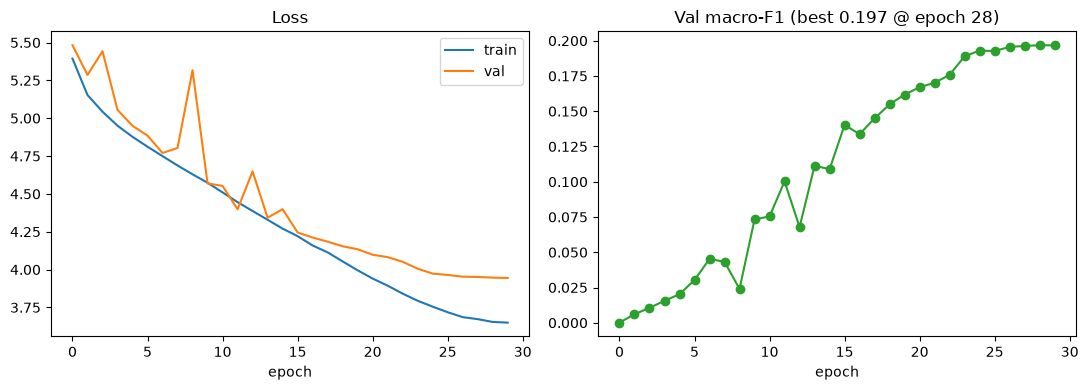

saved 14.2 MB -> MoE_comparisons/models/backbone_3465k_20261119-173642.keras
Uploaded 1 file(s) to durak-dev/ImageClassification@checkpoints: MoE_comparisons/models/backbone_3465k_20261119-173642.keras
To reuse it later, write  BACKBONE_PATH = 'MoE_comparisons/models/backbone_3465k_20261119-173642.keras'


TypeError: make_frozen_backbones() got an unexpected keyword argument 'size'

In [ ]:
# The backbone every head below starts from. The FILE is never changed by a run.
#   path -> load that backbone, e.g. 'MoE_comparisons/models/backbone_6072k_20251118-210000.keras' (either notebook's models/)
#   None -> train a NEW backbone now (saved in MoE_comparisons/models/ under an automatic name, printed below)
BACKBONE_PATH = 'MoE_comparisons/models/backbone_3465k_20261119-173642.keras'

assert BACKBONE_PATH is not None or not USE_SAVED, 'USE_SAVED = True needs BACKBONE_PATH: write the path of the saved backbone'
if BACKBONE_PATH is None:
    BACKBONE_PATH = train_backbone()
    print(f'To reuse it later, write  BACKBONE_PATH = {BACKBONE_PATH!r}')

BACKBONE_PATH = resnet.norm_path(BACKBONE_PATH)
resnet.fetch_if_missing(BACKBONE_PATH, USE_GITHUB)                        # a new pod: download it from GitHub
BACKBONE_ID = os.path.basename(BACKBONE_PATH).removesuffix('.keras')      # part of every log name


def frozen_backbone(inp, augmentation=None):
    """The saved backbone, frozen and in inference mode (batch norm uses its saved statistics): image -> [s1, s2, s3].
    Every model loads its own copy, so no run can change another run's backbone."""
    trunk = tf.keras.models.load_model(BACKBONE_PATH, compile=False)
    trunk.trainable = False
    x = augmentation(inp) if augmentation is not None else inp
    return list(trunk(x, training=False))


_trunk = tf.keras.models.load_model(BACKBONE_PATH, compile=False)
assert _trunk.input_shape[1] == SIZE, f'{BACKBONE_PATH} was trained on {_trunk.input_shape[1]}px images, but SIZE = {SIZE}'
print('using the backbone', BACKBONE_PATH)
print('feature maps (H, W, C):', [tuple(o.shape[1:]) for o in _trunk.outputs])
del _trunk
tf.keras.backend.clear_session()


## 1. CNN (baseline)
```
backbone (s3) -> average over the 8x8 grid -> 256 numbers -> dropout -> Dense(N_EXPERTS x 128, ReLU) -> dropout -> Dense(200)
```
The hidden layer has as many units as all MoE experts together, so the MoE has no extra capacity compared with this baseline.

Epoch 1/10
151/151 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - accuracy: 0.1406 - loss: 4.2182  val macro-F1 0.1514
151/151 ━━━━━━━━━━━━━━━━━━━━ 13s 74ms/step - accuracy: 0.1406 - loss: 4.2182 - val_accuracy: 0.1876 - val_loss: 3.9175 - val_f1: 0.1514
Epoch 2/10
150/151 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - accuracy: 0.1783 - loss: 3.9273  val macro-F1 0.1484
151/151 ━━━━━━━━━━━━━━━━━━━━ 10s 63ms/step - accuracy: 0.1787 - loss: 3.9266 - val_accuracy: 0.1853 - val_loss: 3.9892 - val_f1: 0.1484
Epoch 3/10
150/151 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - accuracy: 0.1842 - loss: 3.9075  val macro-F1 0.1541
151/151 ━━━━━━━━━━━━━━━━━━━━ 10s 63ms/step - accuracy: 0.1840 - loss: 3.9079 - val_accuracy: 0.1803 - val_loss: 4.0114 - val_f1: 0.1541
Epoch 4/10
150/151 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - accuracy: 0.1883 - loss: 3.8573  val macro-F1 0.1649
151/151 ━━━━━━━━━━━━━━━━━━━━ 10s 63ms/step - accuracy: 0.1883 - loss: 3.8568 - val_accuracy: 0.2008 - val_loss: 3.9418 - val_f1: 0.1649
Epoch 5/10
151/151 ━━━━━

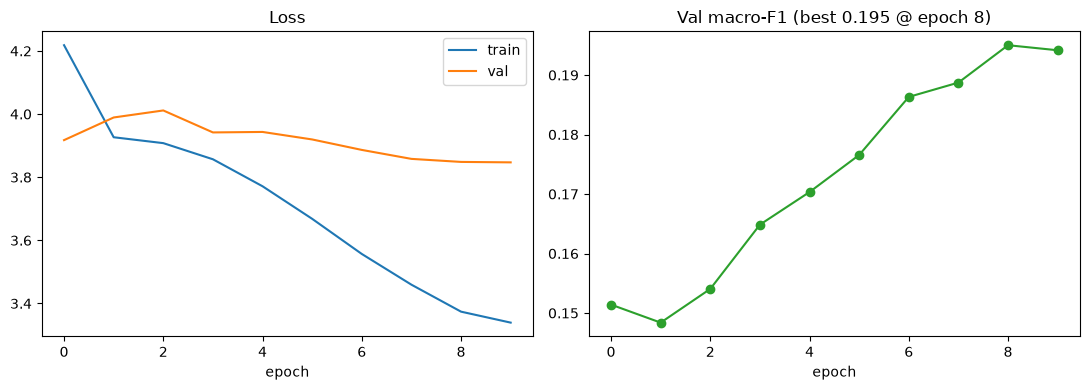

In [35]:
tf.keras.backend.clear_session()
cnn = build_cnn(SIZE, len(classes), frozen_backbone, n_experts=N_EXPERTS, augmentation=AUG, drop=FEATURE_DROP, lr=HEAD_LR)
hist_cnn = run(cnn, f'cnn_{EPOCHS}epochs_{BACKBONE_ID}')

## 2. MoE (soft mixture of experts)
```
256 numbers -> gate:      Dense(N_EXPERTS, softmax)                 -> one weight per expert (they sum to 1)
            -> expert i:  Dense(128, ReLU) -> dropout -> Dense(200) -> class scores
output = sum over experts of  gate weight x expert scores
```
* Every expert runs on every image; the gate only decides how much each one counts.
* A **load-balancing loss** (weight `BALANCE`) rewards using all experts equally. Without it the gate tends to rely on one or two experts.
* While training, the notebook prints the average gate weight per expert (`usage`) and how often each expert has the largest weight (`wins`).

Epoch 1/10
150/151 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step - accuracy: 0.1196 - loss: 4.5063  usage [0.1  0.13 0.14 0.18 0.13 0.13 0.13 0.07]  wins [ 383  719  650 1352  719  633  518  146]
  val macro-F1 0.1466
151/151 ━━━━━━━━━━━━━━━━━━━━ 21s 98ms/step - accuracy: 0.1200 - loss: 4.5037 - val_accuracy: 0.1853 - val_loss: 4.0140 - val_f1: 0.1466
Epoch 2/10
150/151 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step - accuracy: 0.2058 - loss: 3.8206  usage [0.13 0.15 0.12 0.12 0.12 0.11 0.1  0.16]  wins [ 668  961  553  450  560  263  180 1485]
  val macro-F1 0.1702
151/151 ━━━━━━━━━━━━━━━━━━━━ 13s 82ms/step - accuracy: 0.2055 - loss: 3.8204 - val_accuracy: 0.2062 - val_loss: 3.9263 - val_f1: 0.1702
Epoch 3/10
151/151 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step - accuracy: 0.2243 - loss: 3.7017  usage [0.13 0.11 0.1  0.14 0.1  0.14 0.15 0.13]  wins [845 513 158 819 306 755 888 836]
  val macro-F1 0.1787
151/151 ━━━━━━━━━━━━━━━━━━━━ 13s 84ms/step - accuracy: 0.2243 - loss: 3.7017 - val_accuracy: 0.2140 - val_loss: 3.8919

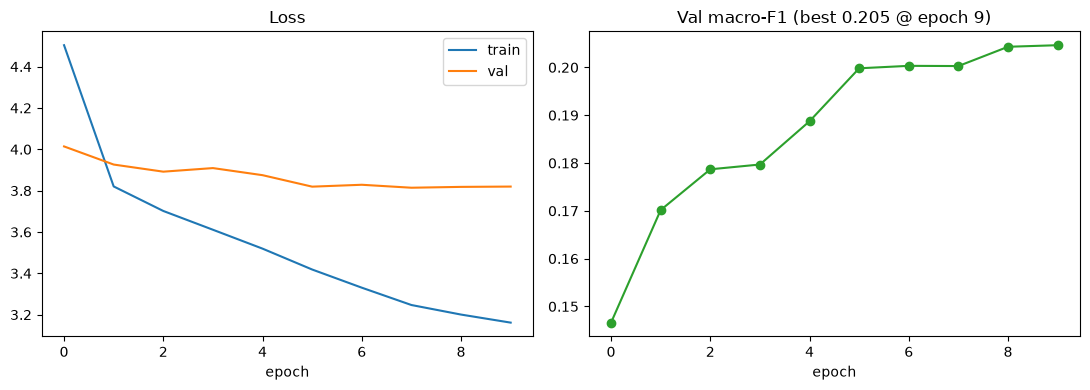

In [36]:
tf.keras.backend.clear_session()
moe_model = build_moe(SIZE, len(classes), frozen_backbone, n_experts=N_EXPERTS, balance=BALANCE, augmentation=AUG,
                      drop=FEATURE_DROP, lr=HEAD_LR)
hist_moe = run(moe_model, f'moe_{EPOCHS}epochs_{BACKBONE_ID}', gate=True)

The plot shows how the gate spreads the images over the experts: left, the average weight of each expert per epoch; right, how even that spread is (1 = all experts equal, 0 = a single expert).

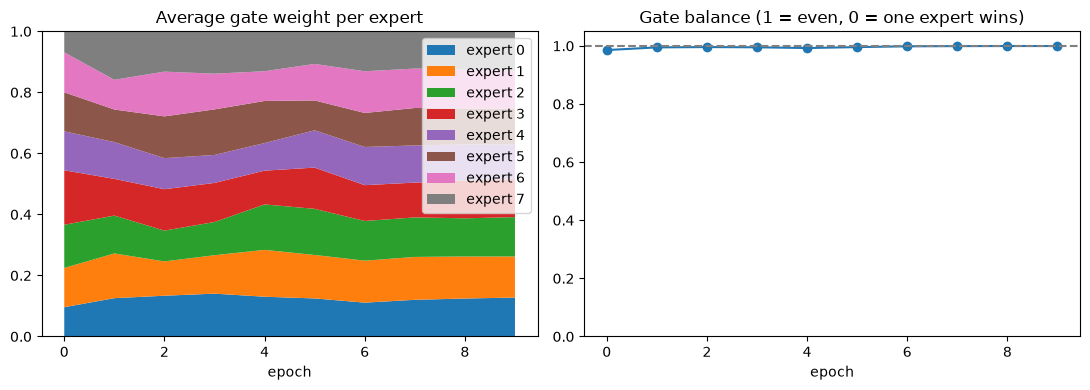

In [37]:
# the gate columns are written into the log by GateMonitor (so this also works with USE_SAVED)
h = hist_moe.history
cols = sorted((c for c in h if c.startswith('gate_usage_')), key=lambda c: int(c.rsplit('_', 1)[1]))
if not cols:
    print('this log has no gate columns (it was trained before GateMonitor wrote them): retrain the MoE to see the plot')
else:
    usage = np.array([h[c] for c in cols]).T          # (epochs, experts)
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].stackplot(range(len(usage)), usage.T, labels=[f"expert {i}" for i in range(usage.shape[1])])
    ax[0].set(title="Average gate weight per expert", xlabel="epoch", ylim=(0, 1))
    ax[0].legend(loc="upper right")

    ax[1].plot(h['gate_balance'], marker="o")
    ax[1].axhline(1, ls="--", c="gray")
    ax[1].set(title="Gate balance (1 = even, 0 = one expert wins)", xlabel="epoch", ylim=(0, 1.05))
    plt.tight_layout(); plt.show()

## 3. pMoE (patch-level routing)
Adapted from *Patch-level Routing in Mixture-of-Experts* (Chowdhury et al., ICML 2023). The 8x8 feature map is treated as 64 patches.
```
for every expert:
    router:   scores all 64 patches and keeps the best L_PATCHES
    expert:   Dense(64, ReLU) -> dropout on each kept patch, weighted average of the patches, Dense(200) -> class scores
output = sum of the experts' scores
```
Each expert looks at only a part of the image, and nothing forces the experts to choose different parts. The two plots after training show **which patches** each expert picked and **how much two experts overlap**.

Epoch 1/10
151/151 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step - accuracy: 0.1418 - loss: 4.2872  val macro-F1 0.1549
151/151 ━━━━━━━━━━━━━━━━━━━━ 22s 97ms/step - accuracy: 0.1418 - loss: 4.2872 - val_accuracy: 0.1907 - val_loss: 3.9507 - val_f1: 0.1549
Epoch 2/10
151/151 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step - accuracy: 0.2431 - loss: 3.5259  val macro-F1 0.1658
151/151 ━━━━━━━━━━━━━━━━━━━━ 12s 82ms/step - accuracy: 0.2431 - loss: 3.5259 - val_accuracy: 0.1984 - val_loss: 3.8868 - val_f1: 0.1658
Epoch 3/10
151/151 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step - accuracy: 0.2757 - loss: 3.3164  val macro-F1 0.1747
151/151 ━━━━━━━━━━━━━━━━━━━━ 13s 83ms/step - accuracy: 0.2757 - loss: 3.3164 - val_accuracy: 0.2044 - val_loss: 3.8975 - val_f1: 0.1747
Epoch 4/10
151/151 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step - accuracy: 0.3039 - loss: 3.1519  val macro-F1 0.1817
151/151 ━━━━━━━━━━━━━━━━━━━━ 12s 79ms/step - accuracy: 0.3039 - loss: 3.1519 - val_accuracy: 0.2094 - val_loss: 3.9242 - val_f1: 0.1817
Epoch 5/10
151/151 ━━━━━

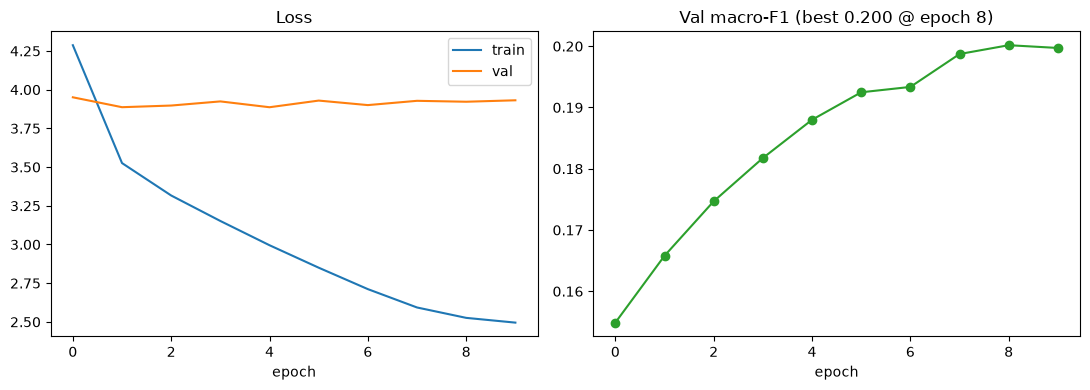

In [38]:
tf.keras.backend.clear_session()
pmoe_model = build_pmoe(SIZE, len(classes), frozen_backbone, n_experts=N_EXPERTS, l=L_PATCHES, augmentation=AUG, lr=HEAD_LR)
hist_pmoe = run(pmoe_model, f'pmoe_{EPOCHS}epochs_{BACKBONE_ID}')

top_idx (64, 8, 8) = (images, experts, l patches);  patch grid (8, 8)
gate values of expert 0 on image 0: [0.426 0.238 0.095 0.085 0.058 0.037 0.031 0.03 ]  (they sum to 1.0 )


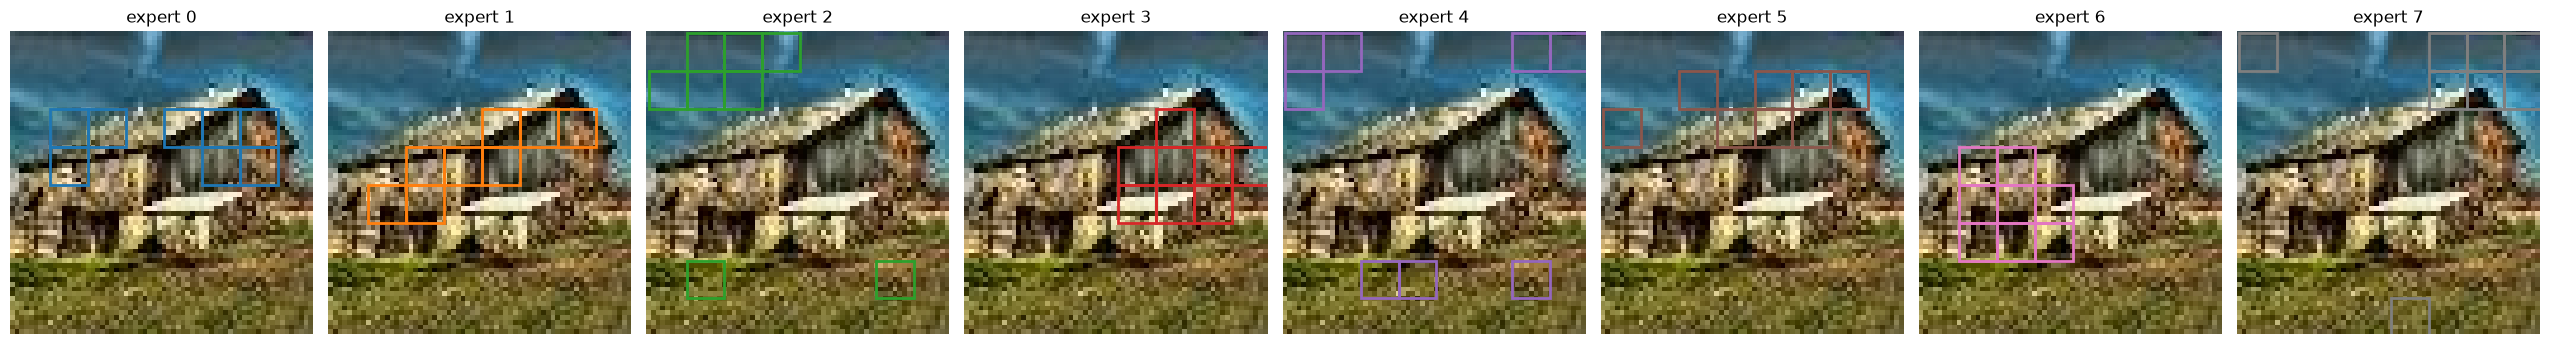

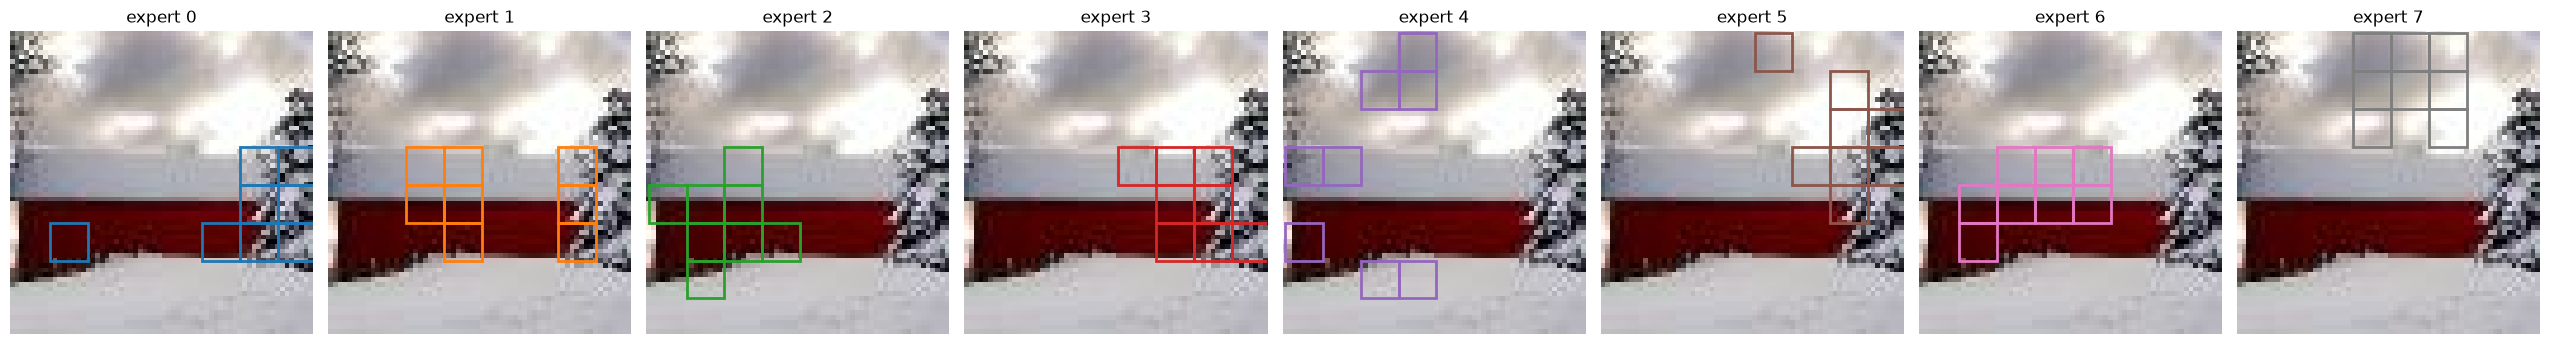

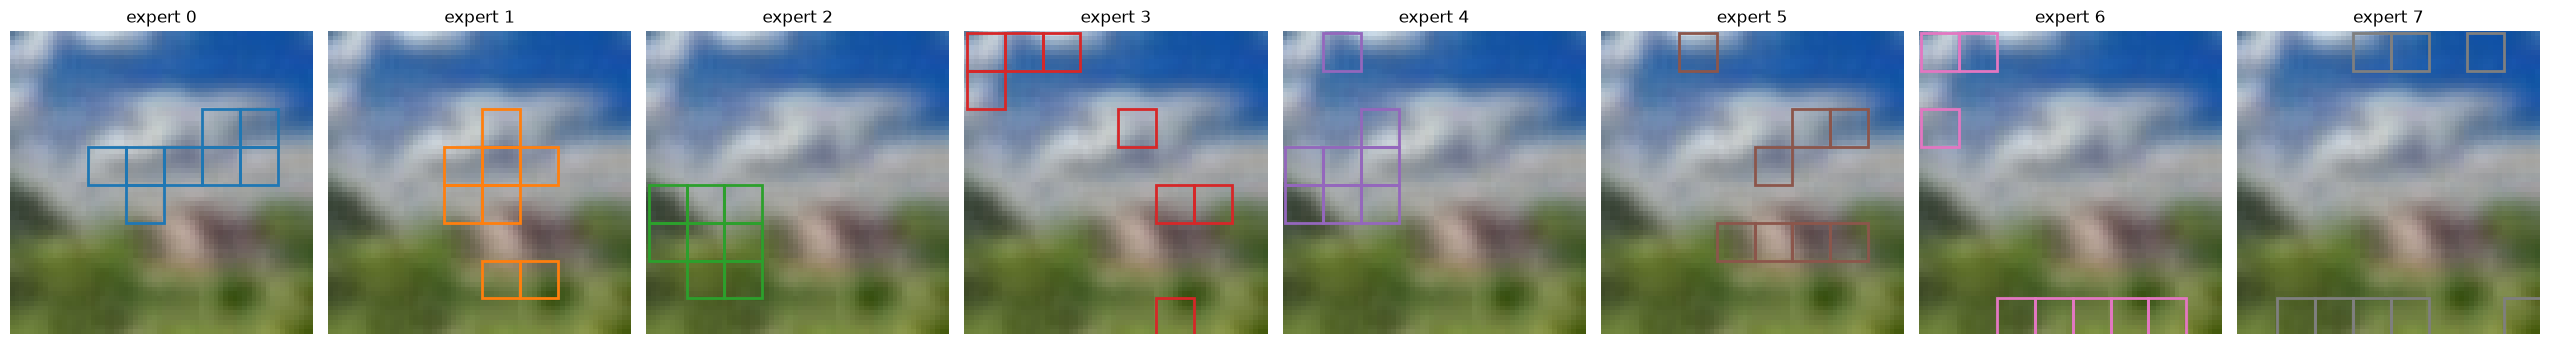

In [39]:
# which patches does each expert pick? one row per image, one panel per expert
images, labels = next(iter(val))
top_idx, gates, grid = expert_choices(pmoe_model, images[:64])
print('top_idx', top_idx.shape, '= (images, experts, l patches);  patch grid', grid)
print('gate values of expert 0 on image 0:', gates[0, 0].round(3), ' (they sum to', gates[0, 0].sum().round(3), ')')

for i in range(3):
    plotting.show_expert_patches(images[i].numpy(), top_idx[i], grid)

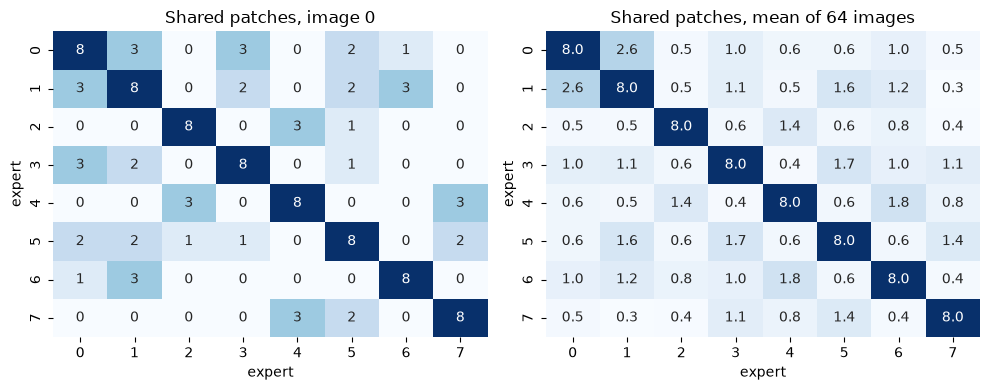

In [40]:
# do the experts pick different patches? number of patches two experts share (the diagonal is l)
# big off-diagonal numbers = the routers did not specialise (pMoE has no balancing loss)
k = top_idx.shape[1]
def overlap(n):
    return np.array([[len(set(top_idx[n, a]) & set(top_idx[n, b])) for b in range(k)] for a in range(k)])

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
sns.heatmap(overlap(0), annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax[0])
ax[0].set(title='Shared patches, image 0', xlabel='expert', ylabel='expert')
sns.heatmap(np.mean([overlap(n) for n in range(len(top_idx))], axis=0), annot=True, fmt='.1f', cmap='Blues', cbar=False, ax=ax[1])
ax[1].set(title=f'Shared patches, mean of {len(top_idx)} images', xlabel='expert', ylabel='expert')
plt.tight_layout(); plt.show()

## 4. MGE (multi-depth experts)
Adapted from Zhang et al., ICCV 2019. One expert per backbone depth, each with its own loss:
```
s1 (32x32x64)   s2 (16x16x128)   s3 (8x8x256)
      |               |               |
   average                 average                  average          (each expert averages its own map)
   dropout                 dropout                  dropout
   Dense(200)         Dense(200)            Dense(200)
   expert_0              expert_1                expert_2
        \_____________|_______________/
              ensemble = mean of the three  (only used to measure the combination)
```
* A **diversity penalty** (weight `DIVERSITY_WEIGHT`) pushes the experts towards different predictions.
* The loss Keras prints is the sum of four cross-entropies plus the penalty, so it is **not comparable** with the loss of the other models. Compare accuracy and macro-F1.

Epoch 1/10
150/151 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - ensemble_accuracy: 0.0932 - ensemble_loss: 4.7294 - expert_0_accuracy: 0.0260 - expert_0_loss: 5.1785 - expert_1_accuracy: 0.0323 - expert_1_loss: 5.3061 - expert_2_accuracy: 0.1302 - expert_2_loss: 4.3796 - loss: 19.6530  val macro-F1 0.1318
151/151 ━━━━━━━━━━━━━━━━━━━━ 15s 79ms/step - ensemble_accuracy: 0.0935 - ensemble_loss: 4.7260 - expert_0_accuracy: 0.0261 - expert_0_loss: 5.1775 - expert_1_accuracy: 0.0324 - expert_1_loss: 5.3032 - expert_2_accuracy: 0.1305 - expert_2_loss: 4.3756 - loss: 19.6441 - val_ensemble_accuracy: 0.1674 - val_ensemble_loss: 4.1679 - val_expert_0_accuracy: 0.0600 - val_expert_0_loss: 4.7776 - val_expert_1_accuracy: 0.0734 - val_expert_1_loss: 4.8071 - val_expert_2_accuracy: 0.2052 - val_expert_2_loss: 3.7735 - val_loss: 17.5302 - val_f1: 0.1318
Epoch 2/10
150/151 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - ensemble_accuracy: 0.1923 - ensemble_loss: 4.0052 - expert_0_accuracy: 0.0543 - expert_0_loss: 4.8567 -

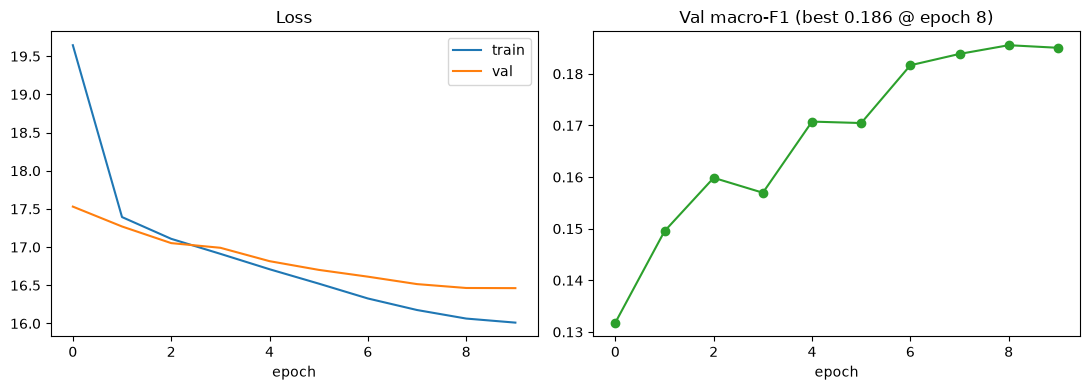

In [41]:
tf.keras.backend.clear_session()
mge_model = build_mge(SIZE, len(classes), frozen_backbone, diversity_weight=DIVERSITY_WEIGHT, augmentation=AUG, lr=HEAD_LR)
hist_mge = run(mge_model, f'mge_{EPOCHS}epochs_{BACKBONE_ID}')

How good is each MGE expert on its own, and what does averaging them give?

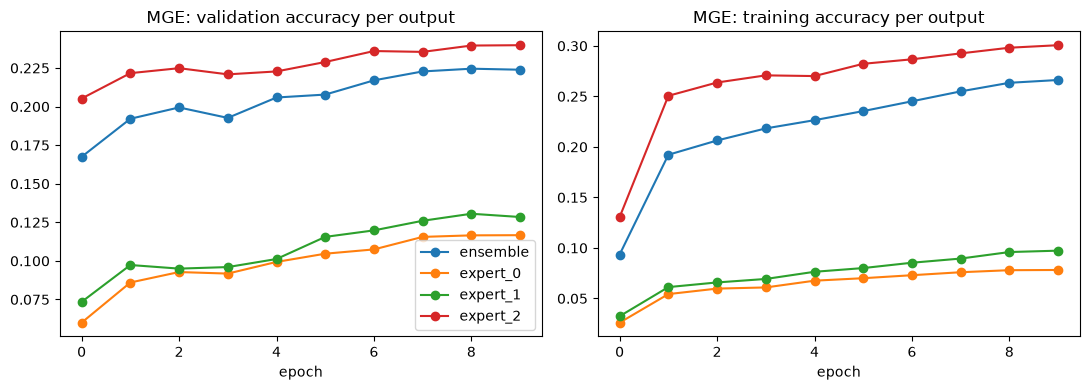

best val accuracy: {'ensemble': 0.2246, 'expert_0': 0.1167, 'expert_1': 0.1306, 'expert_2': 0.2398}


In [42]:
# what does each expert achieve on its own?
h = hist_mge.history
outputs = ['ensemble', 'expert_0', 'expert_1', 'expert_2']

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for name in outputs:
    ax[0].plot(h[f'val_{name}_accuracy'], marker='o', label=name)
    ax[1].plot(h[f'{name}_accuracy'], marker='o', label=name)
ax[0].set(title='MGE: validation accuracy per output', xlabel='epoch')
ax[1].set(title='MGE: training accuracy per output', xlabel='epoch')
ax[0].legend(); plt.tight_layout(); plt.show()
print('best val accuracy:', {n: round(max(h[f'val_{n}_accuracy']), 4) for n in outputs})

## Comparison
Loss (solid = validation, dashed = training), validation macro-F1 and validation accuracy of all four models. For MGE the *ensemble* output is used. Macro-F1 gives each of the 200 classes the same weight, so it is the stricter number.

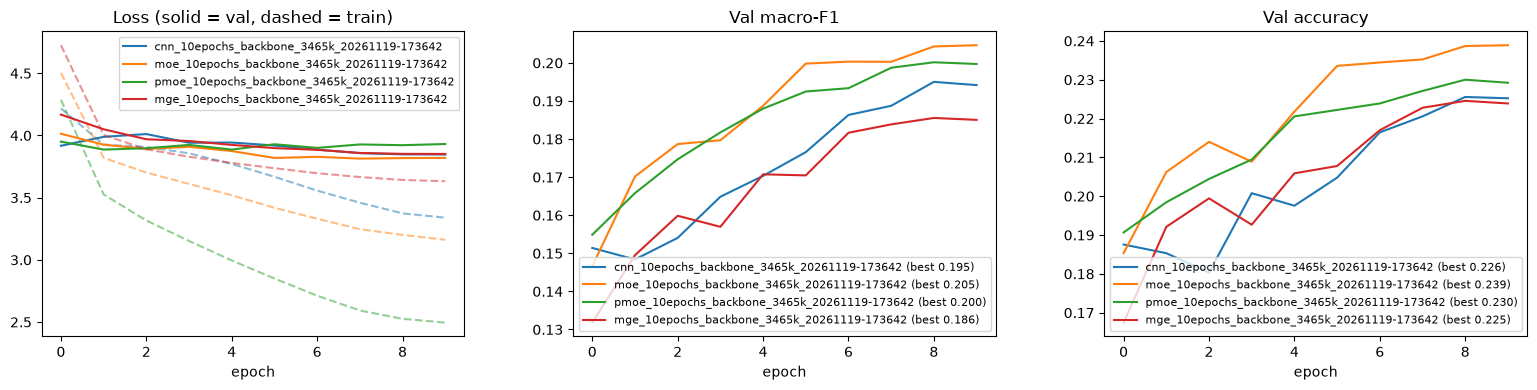

,params,trainable,epochs_run,best_val_acc,best_val_f1,best_f1_epoch,last_train_acc,last_val_acc
model,,,,,,,,
cnn,3934120,468168,10,0.2256,0.1950,9,0.2668,0.2252
moe,3937576,471624,10,0.2389,0.2046,10,0.3047,0.2389
pmoe,3703584,237632,10,0.2300,0.2002,9,0.4189,0.2292
mge,3556152,90200,10,0.2246,0.1855,9,0.2662,0.2239


In [43]:
# the logs of the four models on this backbone (a model that was not trained in this session is read from its log)
names = ['cnn', 'moe', 'pmoe', 'mge']
runs = {m: f'{m}_{EPOCHS}epochs_{BACKBONE_ID}' for m in names}
logs = {m: pd.read_csv(os.path.join(HISTORY_DIR, f'{r}.csv')) for m, r in runs.items()
        if os.path.exists(os.path.join(HISTORY_DIR, f'{r}.csv'))}
plotting.plot_comparison({runs[m]: log for m, log in logs.items()})

nets = {'cnn': globals().get('cnn'), 'moe': globals().get('moe_model'), 'pmoe': globals().get('pmoe_model'), 'mge': globals().get('mge_model')}
rows = []
for name, h in logs.items():
    val_acc = h['val_ensemble_accuracy'] if 'val_ensemble_accuracy' in h else h['val_accuracy']
    train_acc = h['ensemble_accuracy'] if 'ensemble_accuracy' in h else h['accuracy']
    net = nets[name]
    rows.append(dict(model=name,
                     params=net.count_params() if net is not None else None,
                     trainable=int(sum(np.prod(w.shape) for w in net.trainable_weights)) if net is not None else None,
                     epochs_run=len(h), best_val_acc=val_acc.max(), best_val_f1=h['val_f1'].max(),
                     best_f1_epoch=int(h['val_f1'].values.argmax()) + 1,
                     last_train_acc=train_acc.iloc[-1], last_val_acc=val_acc.iloc[-1]))
pd.DataFrame(rows).set_index('model').round(4)

How to read the table: the *train* accuracy is measured with augmentation and dropout switched on, so it is lower than it would be on clean training images. A large gap between train and validation accuracy means overfitting. The kept weights are the epoch with the best validation loss, which is not always the epoch with the best macro-F1.

### What has been the same in every run so far
(The final numbers and the ranking of the models are left out until this version has been run.)
* **MoE:** the gate spreads the images almost evenly over the experts (the balance curve stays close to 1). (The balancing loss asks for this, so it is partly by design.)
* **MGE:** the deeper the expert, the better it is: `expert_0` (shallow) < `expert_1` < `expert_2` (deep).